# VisualSOP Checker — Day 30 V6: Fine-tuned R3D-18 + motion-aware ROI

**Research objective:** improve **six-class assembly activity recognition** compared with V5 (val macro-F1 44.25%; exploratory test 1/16). **80% is an aspirational target, NOT a guaranteed metric.** This is not validated SOP deviation detection. All datasets are read in-place; source videos are neither copied nor redistributed.

Two mandatory Kaggle inputs:
- `/kaggle/input/datasets/wafabila/visualsop-dataset` (9 original camera recordings + coarse labels)
- `/kaggle/input/datasets/wafabila/visualsop-dataset-next` (4 new camera recordings)

**Critical protocol:** group-held-out val 9011/9012; reused exploratory test 9016/9021. The test has been viewed in earlier V1–V5, so it is **not blind**. No tuning based on test. Pretrained R3D-18 is genuinely fine-tuned (layer4 + classifier), in contrast to V5's frozen 512D embeddings + Ridge. New spatial motion ROI is an experimental preprocessing choice; visuals saved for inspection.

## 0. Imports, configuration and environment

Enable a **GPU** and Kaggle **Internet ON** for the official Kinetics-400 checkpoint. Avoid re-running decoding cells unnecessarily: cached clips persist for the current notebook session under `/kaggle/working`.

In [1]:
import os, sys, re, json, time, random, copy, hashlib, zipfile, gc
from pathlib import Path
from collections import Counter
import numpy as np, pandas as pd, cv2, torch, torchvision
import matplotlib.pyplot as plt
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision.models.video import r3d_18, R3D_18_Weights
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from IPython.display import display

SEED=42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
DEVICE=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
if DEVICE.type!='cuda': raise RuntimeError('V6 fine-tuning requires GPU; activate Kaggle GPU accelerator.')
OLD=Path('/kaggle/input/datasets/wafabila/visualsop-dataset')
NEXT=Path('/kaggle/input/datasets/wafabila/visualsop-dataset-next')
for p in (OLD,NEXT):
    if not p.is_dir():raise FileNotFoundError('Kaggle Add Input missing: '+str(p))
OUT=Path('/kaggle/working/VisualSOP_Day30_V6_FINETUNE')
for folder in ('audit','cache','models','reports','plots','predictions','metadata','examples'):(OUT/folder).mkdir(parents=True,exist_ok=True)
print('DEVICE',DEVICE,torch.cuda.get_device_name(0))
print('Python',sys.version.split()[0],'torch',torch.__version__,'torchvision',torchvision.__version__,'OpenCV',cv2.__version__)
print('INPUTS',OLD,NEXT)

DEVICE cuda Tesla T4
Python 3.13.15 torch 2.11.0+cu128 torchvision 0.26.0+cu128 OpenCV 4.14.0
INPUTS /kaggle/input/datasets/wafabila/visualsop-dataset /kaggle/input/datasets/wafabila/visualsop-dataset-next


## 1. Strict session and annotation audit

We require exactly **9 original + 4 NEXT** unique source recordings. We use the **30 FPS** annotation index timebase and preserve the historical toy-group split.

In [2]:
EXPECTED_NEXT={
'nusar-2021_action_both_9014-b02a_9014_user_id_2021-02-02_143628',
'nusar-2021_action_both_9015-c03a_9015_user_id_2021-02-02_163503',
'nusar-2021_action_both_9022-c03e_9022_user_id_2021-02-23_111647',
'nusar-2021_action_both_9014-c01b_9014_user_id_2021-02-02_150612'}
old_v=sorted(p for p in OLD.rglob('C10095_rgb.mp4') if p.is_file() and '.cache' not in p.parts)
next_v=sorted(p for p in NEXT.rglob('C10095_rgb.mp4') if p.is_file() and '.cache' not in p.parts)
old_s={p.parent.name for p in old_v};next_s={p.parent.name for p in next_v}
assert len(old_v)==len(old_s)==9, f'OLD found {len(old_v)} files and {len(old_s)} sessions'
assert len(next_v)==len(next_s)==4 and next_s==EXPECTED_NEXT, f'NEXT sessions unexpected: {next_s}'
assert not old_s&next_s
by_session={p.parent.name:p for p in old_v+next_v}
anns={}
for base in (OLD,NEXT):
    for p in base.rglob('*.txt'):
        if 'coarse_labels' not in p.parts or '.cache' in p.parts:continue
        if not re.fullmatch(r'(assembly|disassembly)_.+\.txt',p.name):continue
        if p.name in anns and p.read_bytes()!=anns[p.name].read_bytes():raise RuntimeError('Conflicting duplicate annotation '+p.name)
        anns[p.name]=p
assert len(anns)==680, f'Expected 680 coarse labels, got {len(anns)}'
print('[PASS] 9 OLD + 4 NEXT = 13 distinct sessions; annotations:',len(anns))
inv=pd.DataFrame([{'session':s,'source':'NEXT' if s in next_s else 'OLD','size_GiB':round(p.stat().st_size/1024**3,3)} for s,p in sorted(by_session.items())]);display(inv)
inv.to_csv(OUT/'audit'/'session_inventory.csv',index=False)

[PASS] 9 OLD + 4 NEXT = 13 distinct sessions; annotations: 680


,session,source,size_GiB
0,nusar-2021_action_both_9011-a01_9011_user_id_2...,OLD,0.768
1,nusar-2021_action_both_9011-b06b_9011_user_id_...,OLD,0.644
2,nusar-2021_action_both_9012-a16_9012_user_id_2...,OLD,1.160
3,nusar-2021_action_both_9013-a02_9013_user_id_2...,OLD,1.772
4,nusar-2021_action_both_9014-a12_9014_user_id_2...,OLD,1.341
5,nusar-2021_action_both_9014-b02a_9014_user_id_...,NEXT,1.067
6,nusar-2021_action_both_9014-c01b_9014_user_id_...,NEXT,1.583
7,nusar-2021_action_both_9015-a08_9015_user_id_2...,OLD,1.177
8,nusar-2021_action_both_9015-c03a_9015_user_id_...,NEXT,1.022
9,nusar-2021_action_both_9016-a24_9016_user_id_2...,OLD,0.703


## 2. Parse intervals, verify timestamps and lock split

No random frame split: train/validation/test are disjoint by **toy group**, and the four NEXT sessions are training only. Real independent source segments, not augmented views, determine sample counts.

In [3]:
GROUPS={'train':{'9013','9014','9015','9022'},'val':{'9011','9012'},'test':{'9016','9021'}}
group_map={g:sp for sp,gs in GROUPS.items() for g in gs}
CLASSES=sorted(['attach cabin','detach cabin','attach wheel','detach wheel','screw chassis','unscrew chassis'])
class_to_idx={c:i for i,c in enumerate(CLASSES)}
rows=[]; invalid=[]; ann_sessions=set()
for filename,p in sorted(anns.items()):
    mt=re.fullmatch(r'(assembly|disassembly)_(.+)\.txt',filename)
    if not mt:continue
    phase,session=mt.groups();ann_sessions.add(session)
    if session not in by_session:continue
    m=re.findall(r'(?<!\d)(90\d{2})(?!\d)',session)
    if not m: raise RuntimeError('Cannot infer toy group '+session)
    group=m[0]
    if group not in group_map:raise RuntimeError('Unexpected toy group '+group)
    for line_no,line in enumerate(p.read_text(encoding='utf-8-sig',errors='replace').splitlines(),1):
        parts=line.split('\t',2)
        if len(parts)!=3: invalid.append([filename,line_no,'tab fields']);continue
        try:a,b=int(parts[0].strip()),int(parts[1].strip())
        except ValueError: invalid.append([filename,line_no,'noninteger']);continue
        action=' '.join(parts[2].split()).casefold()
        if a<0 or b<=a or not action:invalid.append([filename,line_no,'invalid interval']);continue
        if action in class_to_idx:
            rows.append(dict(session=session,source='NEXT' if session in next_s else 'OLD',toy_group=group,split=group_map[group],phase=phase,action=action,class_id=class_to_idx[action],start_s=a/30.,end_s=b/30.,video_path=str(by_session[session])))
df=pd.DataFrame(rows).sort_values(['session','start_s','phase','action']).reset_index(drop=True)
df.insert(0,'segment_id',[f'seg_{i:05d}' for i in range(len(df))])
assert not df.empty and len(invalid)==0,f'Invalid labels: {invalid[:5]}'
assert set(df.session)==set(by_session)
assert df.groupby('toy_group').split.nunique().max()==1
assert df[df.source=='NEXT'].split.eq('train').all()
assert df.groupby('split').size().to_dict()=={'test':16,'train':62,'val':17},f'Count mismatch: {df.groupby("split").size().to_dict()}'
assert int((df.source=='NEXT').sum())==30
meta=[]
for s,path in by_session.items():
    cap=cv2.VideoCapture(str(path));ok=cap.isOpened()
    fps=cap.get(cv2.CAP_PROP_FPS) if ok else 0;count=cap.get(cv2.CAP_PROP_FRAME_COUNT) if ok else 0
    duration=count/fps if fps>0 else 0
    cap.release()
    if not ok or duration<=0:raise RuntimeError('Video unreadable '+s)
    meta.append(dict(session=s,fps=fps,duration_s=duration))
vm=pd.DataFrame(meta)
endmap=vm.set_index('session').duration_s.to_dict()
failed=df[(df.apply(lambda r:r.end_s>endmap[r.session]+0.2 or r.start_s>=endmap[r.session],axis=1))]
if len(failed):raise RuntimeError('Out-of-video bounds segments: '+str(len(failed)))
df.to_csv(OUT/'audit'/'segments.csv',index=False);vm.to_csv(OUT/'audit'/'video_metadata.csv',index=False)
pd.DataFrame({'unmatched_annotation_session':sorted(ann_sessions-set(by_session))}).to_csv(OUT/'audit'/'unmatched_annotation_sessions.csv',index=False)
print('Real source segments',df.groupby('split').size().to_dict(),'; added NEXT',int((df.source=='NEXT').sum()))
display(pd.crosstab(df.action,df.split).reindex(index=CLASSES,columns=['train','val','test'],fill_value=0))

Real source segments {'test': 16, 'train': 62, 'val': 17} ; added NEXT 30


split,train,val,test
action,,,
attach cabin,10,3,4
attach wheel,9,2,2
detach cabin,10,3,4
detach wheel,8,2,2
screw chassis,15,4,2
unscrew chassis,10,3,2


## 3. Decode original source clips **once** into reusable frame cache

**Preprocessing improvement:** in addition to center ROI, construct a **motion-guided ROI** from inter-frame changes, which may recover hands/tools missed by center cropping. Save one temporal view of validation/test and two train views. The cache is local to `/kaggle/working` and is excluded from the final ZIP. Preview evidence is exported. No source video copying.

This step may take substantial time due to random seeks on large MP4s. When re-running in the same session, completed cache files are reused. Do not assume motion ROI is beneficial: the next stage measures that on validation.

Decoded 10 / 95 seconds 151
Decoded 20 / 95 seconds 364
Decoded 30 / 95 seconds 695
Decoded 40 / 95 seconds 1045
Decoded 50 / 95 seconds 1372
Decoded 60 / 95 seconds 1701
Decoded 70 / 95 seconds 1959
Decoded 80 / 95 seconds 2117
Decoded 90 / 95 seconds 2369
Cache clip views 157 expected 157; bytes 144.7 MiB


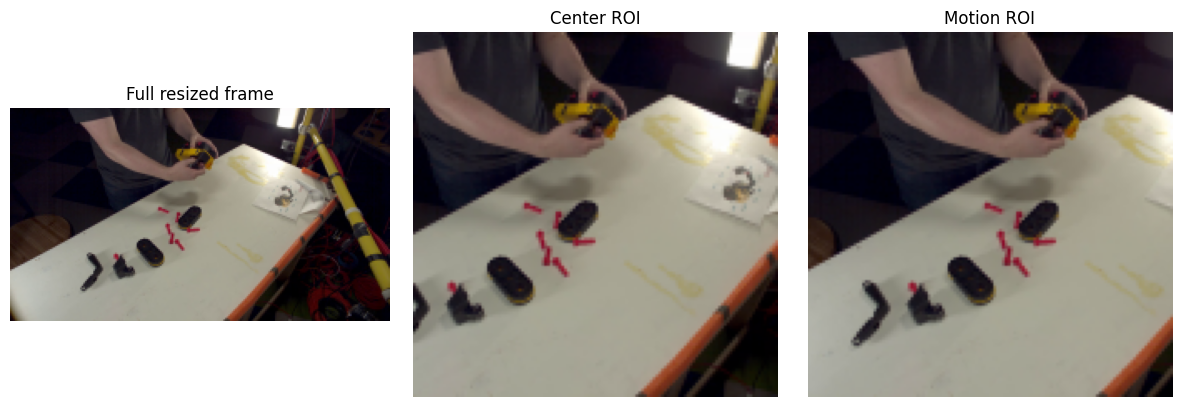

In [4]:
T=16; RESIZE_SHORT=128
TRAIN_POS=(0.25,0.75); EVAL_POS=(0.50,)
def decode_frames(video_path,start,end,position):
    duration=end-start
    if duration<=0:raise ValueError('Invalid segment')
    span=duration*.78; left=start+(duration-span)*position
    times=np.linspace(left+span*.015,left+span*.985,T)
    cap=cv2.VideoCapture(str(video_path));frames=[]
    try:
        if not cap.isOpened():raise RuntimeError('Cannot open video '+str(video_path))
        for t in times:
            cap.set(cv2.CAP_PROP_POS_MSEC,float(t)*1000)
            ok,bgr=cap.read()
            if not ok:raise RuntimeError(f'Decode failed at {t:.2f}s')
            h,w=bgr.shape[:2]; scale=RESIZE_SHORT/min(h,w)
            nw=max(RESIZE_SHORT,int(round(w*scale))); nh=max(RESIZE_SHORT,int(round(h*scale)))
            im=cv2.resize(bgr,(nw,nh),interpolation=cv2.INTER_AREA)
            frames.append(cv2.cvtColor(im,cv2.COLOR_BGR2RGB))
    finally:cap.release()
    return np.stack(frames).astype('uint8')

def square_crop(seq,mode='center'):
    # frames: T,H,W,3 already short-edge resized to 128
    t,h,w,_=seq.shape;size=min(h,w)
    cx,cy=w/2,h/2
    if mode=='motion':
        gray=np.stack([cv2.cvtColor(f,cv2.COLOR_RGB2GRAY) for f in seq]).astype('float32')
        diff=np.mean(np.abs(np.diff(gray,axis=0)),axis=0)
        # Restrict visual changes to reliable high-motion locations, and avoid boundary artifacts
        margin=max(2,int(min(h,w)*.04));diff[:margin]=0;diff[-margin:]=0;diff[:,:margin]=0;diff[:,-margin:]=0
        threshold=np.percentile(diff,90)
        yy,xx=np.where((diff>=threshold)&(diff>1.5))
        if len(xx)>=20:
            weights=diff[yy,xx]
            cx=float(np.average(xx,weights=weights));cy=float(np.average(yy,weights=weights))
    x=int(np.clip(round(cx-size/2),0,w-size));y=int(np.clip(round(cy-size/2),0,h-size))
    return seq[:,y:y+size,x:x+size,:].copy()

cache_index={};t0=time.time()
for i,r in enumerate(df.itertuples(index=False),1):
    for j,pos in enumerate(TRAIN_POS if r.split=='train' else EVAL_POS):
        key=f'{r.segment_id}_v{j}';cache=OUT/'cache'/(key+'.npz')
        if cache.exists():
            try:
                with np.load(cache) as z:
                    assert z['frames'].shape[0]==T
            except Exception:
                cache.unlink()
        if not cache.exists():
            frames=decode_frames(r.video_path,r.start_s,r.end_s,pos)
            np.savez_compressed(cache,frames=frames)
        cache_index[key]={'segment_id':r.segment_id,'view_index':j,'split':r.split,'class_id':int(r.class_id),'action':r.action,'session':r.session,'cache_path':str(cache)}
    if i%10==0:print('Decoded',i,'/',len(df),'seconds',round(time.time()-t0))
index=pd.DataFrame(cache_index.values())
index.to_csv(OUT/'audit'/'cached_clips.csv',index=False)
print('Cache clip views',len(index),'expected 157; bytes',round(sum(p.stat().st_size for p in (OUT/'cache').glob('*.npz'))/1024**2,1),'MiB')
assert len(index)==157
# Visual check: center vs motion ROI from a real source segment
with np.load(index.iloc[0].cache_path) as z:sample=z['frames']
fig,axes=plt.subplots(1,3,figsize=(12,4))
for ax,img,title in zip(axes,[sample[T//2],square_crop(sample,'center')[T//2],square_crop(sample,'motion')[T//2]],['Full resized frame','Center ROI','Motion ROI']):
    ax.imshow(img);ax.set_title(title);ax.axis('off')
fig.tight_layout();fig.savefig(OUT/'examples'/'center_vs_motion_roi.jpg',dpi=140);plt.show();plt.close(fig)

## 4. Trainable model and reproducible transforms

Use the **official pretrained Kinetics-400 R3D-18**. Freeze layers 1–3; fine-tune **layer4 + six-class head**. Train examples use center/motion ROI as an augmentation, while validation compares center, motion, and averaged predictions. These alternatives are selected exclusively on validation. Class weights use training only. BatchNorm running statistics are frozen due to small batches.

In [5]:
weights=R3D_18_Weights.DEFAULT
try:
    backbone=r3d_18(weights=weights)
except Exception as e:
    raise RuntimeError('Official weights unavailable. Kaggle Internet ON; no random fallback.') from e
transform=weights.transforms()
backbone.fc=nn.Linear(512,len(CLASSES))
for p in backbone.parameters():p.requires_grad_(False)
for p in backbone.layer4.parameters():p.requires_grad_(True)
for p in backbone.fc.parameters():p.requires_grad_(True)
backbone=backbone.to(DEVICE)
# Capture initialization, so any run starts from identical checkpoint
BASE_STATE={k:v.detach().cpu().clone() for k,v in backbone.state_dict().items()}

def process_clip(frames,mode):
    crop=square_crop(frames,mode)
    uint8=torch.from_numpy(crop.copy()).permute(0,3,1,2).contiguous()
    x=transform(uint8)
    if x.shape!=(3,16,112,112):raise RuntimeError('Unexpected shape: '+str(x.shape))
    return x

class ClipDataset(Dataset):
    def __init__(self,records,training=False,mode='center'):
        self.records=records.reset_index(drop=True);self.training=training;self.mode=mode
    def __len__(self):return len(self.records)
    def __getitem__(self,i):
        r=self.records.iloc[i]
        with np.load(r.cache_path) as z:frames=z['frames']
        if self.training:
            mode=random.choice(('center','motion'))
        else:mode=self.mode
        x=process_clip(frames,mode)
        return x, int(r.class_id), str(r.segment_id)

train_idx=index[index.split=='train'];val_idx=index[index.split=='val'];test_idx=index[index.split=='test']
train_loader=DataLoader(ClipDataset(train_idx,True),batch_size=2,shuffle=True,num_workers=0,pin_memory=True)
val_center_loader=DataLoader(ClipDataset(val_idx,False,'center'),batch_size=2,shuffle=False,num_workers=0)
val_motion_loader=DataLoader(ClipDataset(val_idx,False,'motion'),batch_size=2,shuffle=False,num_workers=0)
print('Train views',len(train_idx),'val',len(val_idx),'test',len(test_idx))
assert len(train_idx)==124 and len(val_idx)==17 and len(test_idx)==16
train_counts=np.bincount(train_idx.class_id.to_numpy(),minlength=len(CLASSES))
class_weight=np.sqrt(train_counts.sum()/np.maximum(train_counts,1)/len(CLASSES))
class_weight=class_weight/class_weight.mean()
print('Class counts',dict(zip(CLASSES,train_counts.tolist())),'class weights',np.round(class_weight,2))
LOSS=nn.CrossEntropyLoss(weight=torch.tensor(class_weight,dtype=torch.float32,device=DEVICE),label_smoothing=.02)

def set_train_mode(model):
    model.train()
    for module in model.modules():
        if isinstance(module,nn.modules.batchnorm._BatchNorm):module.eval()

@torch.no_grad()
def logits_for(model,loader):
    model.eval();ys=[];ids=[];scores=[]
    for x,y,segment_ids in loader:
        logits=model(x.to(DEVICE)).float().cpu().numpy()
        scores.append(logits);ys.extend(y.numpy().tolist());ids.extend(segment_ids)
    return np.concatenate(scores),np.array(ys),ids

def score(y,prob):
    pred=prob.argmax(axis=1)
    return {'accuracy':float(accuracy_score(y,pred)),
            'balanced_accuracy':float(balanced_accuracy_score(y,pred)),
            'macro_f1':float(f1_score(y,pred,labels=np.arange(len(CLASSES)),average='macro',zero_division=0))}

Downloading: "https://download.pytorch.org/models/r3d_18-b3b3357e.pth" to /root/.cache/torch/hub/checkpoints/r3d_18-b3b3357e.pth


100%|██████████| 127M/127M [00:00<00:00, 192MB/s]


Train views 124 val 17 test 16
Class counts {'attach cabin': 20, 'attach wheel': 18, 'detach cabin': 20, 'detach wheel': 16, 'screw chassis': 30, 'unscrew chassis': 20} class weights [1.   1.06 1.   1.12 0.82 1.  ]


## 5. Fine-tune pretrained temporal features with early stopping

Train for up to **12 epochs**, save the best by **validation macro-F1**, then validation accuracy as a tie-breaker. The test set is **not touched** here. Re-running will overwrite the experiment's checkpoint; keep the archive after completion. Runtime depends on Kaggle GPU/decoding and is not guaranteed.

Epoch 1 loss 1.8389 val winner ensemble {'accuracy': 0.35294117647058826, 'balanced_accuracy': 0.29166666666666663, 'macro_f1': 0.24090909090909088} elapsed min 0.1
Epoch 2 loss 1.5342 val winner motion {'accuracy': 0.23529411764705882, 'balanced_accuracy': 0.18055555555555555, 'macro_f1': 0.12121212121212122} elapsed min 0.2
Epoch 3 loss 1.2441 val winner ensemble {'accuracy': 0.35294117647058826, 'balanced_accuracy': 0.3055555555555555, 'macro_f1': 0.3055555555555555} elapsed min 0.3
Epoch 4 loss 0.9306 val winner motion {'accuracy': 0.29411764705882354, 'balanced_accuracy': 0.23611111111111108, 'macro_f1': 0.19047619047619047} elapsed min 0.4
Epoch 5 loss 0.699 val winner motion {'accuracy': 0.47058823529411764, 'balanced_accuracy': 0.4583333333333333, 'macro_f1': 0.41984126984126985} elapsed min 0.4
Epoch 6 loss 0.46 val winner ensemble {'accuracy': 0.47058823529411764, 'balanced_accuracy': 0.4305555555555556, 'macro_f1': 0.42777777777777776} elapsed min 0.5
Epoch 7 loss 0.318 val 

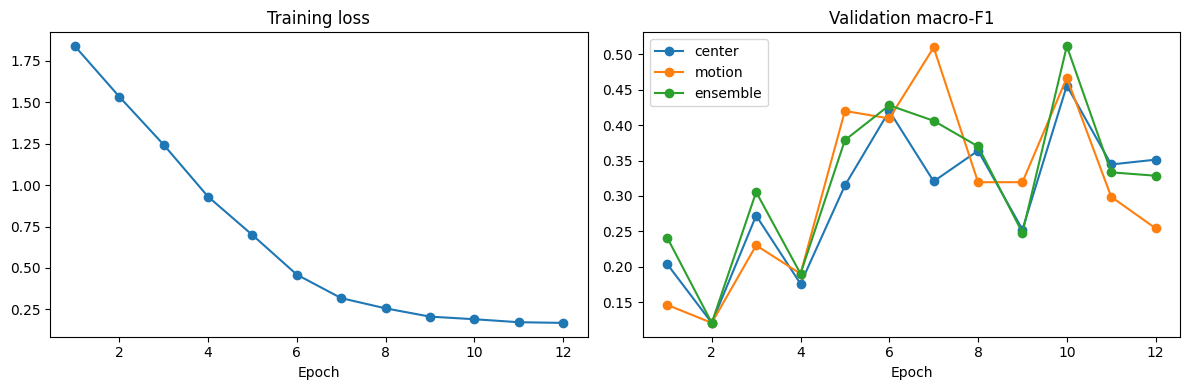

In [6]:
EPOCHS=12;PATIENCE=4
model=backbone
model.load_state_dict(BASE_STATE)
optimizer=torch.optim.AdamW([
    {'params':model.layer4.parameters(),'lr':1e-5},
    {'params':model.fc.parameters(),'lr':2e-4}],weight_decay=1e-3)
scheduler=torch.optim.lr_scheduler.CosineAnnealingLR(optimizer,T_max=EPOCHS,eta_min=1e-6)
scaler=torch.amp.GradScaler('cuda',enabled=(DEVICE.type=='cuda'))
history=[];best_key=(-1.,-1.);stale=0
checkpoint=OUT/'models'/'best_finetuned_layer4_fc.pt'
start=time.time()
for epoch in range(1,EPOCHS+1):
    set_train_mode(model);running=0;nseen=0
    for x,y,_ in train_loader:
        x=x.to(DEVICE,non_blocking=True);y=y.to(DEVICE)
        optimizer.zero_grad(set_to_none=True)
        with torch.autocast(device_type='cuda',enabled=(DEVICE.type=='cuda')):
            out=model(x);loss=LOSS(out,y)
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(list(model.layer4.parameters())+list(model.fc.parameters()),1.)
        scaler.step(optimizer);scaler.update()
        running+=loss.item()*len(y);nseen+=len(y)
    scheduler.step()
    zc,yy,ids=logits_for(model,val_center_loader)
    zm,yy2,ids2=logits_for(model,val_motion_loader)
    assert np.array_equal(yy,yy2) and ids==ids2
    variants={'center':zc,'motion':zm,'ensemble':(zc+zm)/2}
    metrics={k:score(yy,v) for k,v in variants.items()}
    best_variant=max(variants,key=lambda k:(metrics[k]['macro_f1'],metrics[k]['accuracy'],k))
    key=(metrics[best_variant]['macro_f1'],metrics[best_variant]['accuracy'])
    history.append({'epoch':epoch,'train_loss':running/max(nseen,1),'val_variant':best_variant,**{('val_'+k+'_'+metric):v for k,d in metrics.items() for metric,v in d.items()}})
    print('Epoch',epoch,'loss',round(running/max(nseen,1),4),'val winner',best_variant,metrics[best_variant],'elapsed min',round((time.time()-start)/60,1))
    if key>best_key:
        best_key=key;stale=0
        torch.save({'layer4':model.layer4.state_dict(),'fc':model.fc.state_dict(),'best_epoch':epoch,'val_variant':best_variant,'class_names':CLASSES,'selection_metrics':metrics[best_variant],'seed':SEED},checkpoint)
    else:
        stale+=1
    if stale>=PATIENCE:
        print('Validation early stopping at epoch',epoch);break
hist=pd.DataFrame(history);hist.to_csv(OUT/'reports'/'training_history.csv',index=False)
print('Best validation key',best_key,'checkpoint',checkpoint,'MiB',round(checkpoint.stat().st_size/1024**2,2))
fig,axes=plt.subplots(1,2,figsize=(12,4))
axes[0].plot(hist.epoch,hist.train_loss,marker='o');axes[0].set_title('Training loss');axes[0].set_xlabel('Epoch')
for variant in ('center','motion','ensemble'):axes[1].plot(hist.epoch,hist[f'val_{variant}_macro_f1'],marker='o',label=variant)
axes[1].set_title('Validation macro-F1');axes[1].legend();axes[1].set_xlabel('Epoch');fig.tight_layout();fig.savefig(OUT/'plots'/'learning_curves.png',dpi=150);plt.show();plt.close(fig)

## 6. Locked best model: validation predictions then **one exploratory test evaluation**

The previously inspected test groups are reported **only once here** after validation-based checkpoint and ROI choice have been fixed. Do not use these test results to tweak the model and then call the test independent.

Locked best epoch 10 ROI variant ensemble
VALIDATION: {'accuracy': 0.5294117647058824, 'balanced_accuracy': 0.513888888888889, 'macro_f1': 0.5111111111111111}
REUSED EXPLORATORY TEST (not blind): {'accuracy': 0.1875, 'balanced_accuracy': 0.16666666666666666, 'macro_f1': 0.1111111111111111}
Correct test: 3 of 16 — 80% requires 13/16


,segment_id,session,action,split,prediction,correct,predicted_margin
117,seg_00067,nusar-2021_action_both_9016-a24_9016_user_id_2...,detach wheel,test,unscrew chassis,False,0.104842
118,seg_00068,nusar-2021_action_both_9016-a24_9016_user_id_2...,attach wheel,test,screw chassis,False,0.737080
119,seg_00069,nusar-2021_action_both_9021-a14_9021_user_id_2...,detach wheel,test,unscrew chassis,False,0.526228
120,seg_00070,nusar-2021_action_both_9021-a14_9021_user_id_2...,unscrew chassis,test,attach cabin,False,1.644620
121,seg_00071,nusar-2021_action_both_9021-a14_9021_user_id_2...,detach cabin,test,unscrew chassis,False,0.255139
122,seg_00072,nusar-2021_action_both_9021-a14_9021_user_id_2...,attach cabin,test,screw chassis,False,1.172199
123,seg_00073,nusar-2021_action_both_9021-a14_9021_user_id_2...,detach cabin,test,attach cabin,False,0.619387
124,seg_00074,nusar-2021_action_both_9021-a14_9021_user_id_2...,attach cabin,test,screw chassis,False,0.949816
125,seg_00075,nusar-2021_action_both_9021-a14_9021_user_id_2...,detach cabin,test,screw chassis,False,0.581503
126,seg_00076,nusar-2021_action_both_9021-a14_9021_user_id_2...,attach cabin,test,attach cabin,True,0.598555


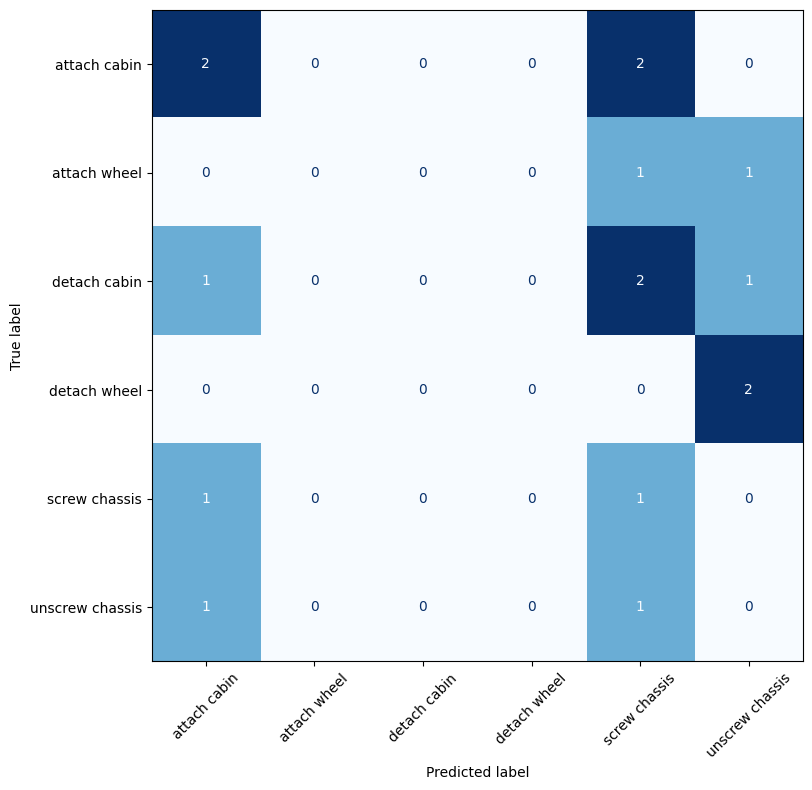

849

In [7]:
ckpt=torch.load(checkpoint,map_location='cpu',weights_only=False)
model.load_state_dict(BASE_STATE)
model.layer4.load_state_dict(ckpt['layer4']);model.fc.load_state_dict(ckpt['fc'])
variant=ckpt['val_variant'];print('Locked best epoch',ckpt['best_epoch'],'ROI variant',variant)

def predict_locked(records):
    out={}
    for mode in ('center','motion'):
        scores,yy,ids=logits_for(model,DataLoader(ClipDataset(records,False,mode),batch_size=2,shuffle=False,num_workers=0))
        out[mode]=(scores,yy,ids)
    assert np.array_equal(out['center'][1],out['motion'][1]) and out['center'][2]==out['motion'][2]
    zc,y,ids=out['center'];zm=out['motion'][0]
    selected={'center':zc,'motion':zm,'ensemble':(zc+zm)/2}[variant]
    return selected,y,ids

val_logit,val_y,val_ids=predict_locked(val_idx)
test_logit,test_y,test_ids=predict_locked(test_idx)
val_metrics=score(val_y,val_logit);test_metrics=score(test_y,test_logit)
print('VALIDATION:',val_metrics)
print('REUSED EXPLORATORY TEST (not blind):',test_metrics)
print('Correct test:',int((test_logit.argmax(1)==test_y).sum()),'of',len(test_y),'— 80% requires 13/16')

def save_predictions(records,logits,y,ids,filename):
    predicted=logits.argmax(1)
    if records.segment_id.tolist()!=ids:raise RuntimeError('Prediction order mismatch')
    out=records[['segment_id','session','action','split']].copy()
    out['prediction']=[CLASSES[int(i)] for i in predicted]
    out['correct']=(predicted==y)
    out['predicted_margin']=np.sort(logits,axis=1)[:,-1]-np.sort(logits,axis=1)[:,-2]
    out.to_csv(OUT/'predictions'/filename,index=False)
    return out
val_pred=save_predictions(val_idx,val_logit,val_y,val_ids,'validation_predictions.csv')
test_pred=save_predictions(test_idx,test_logit,test_y,test_ids,'reused_exploratory_test_predictions.csv')
display(test_pred)
cm=confusion_matrix(test_y,test_logit.argmax(1),labels=range(len(CLASSES)))
pd.DataFrame(cm,index=CLASSES,columns=CLASSES).to_csv(OUT/'reports'/'test_confusion_matrix.csv')
classification_report_dict=classification_report(test_y,test_logit.argmax(1),labels=list(range(len(CLASSES))),target_names=CLASSES,output_dict=True,zero_division=0)
pd.DataFrame(classification_report_dict).T.to_csv(OUT/'reports'/'test_per_class.csv')
fig,ax=plt.subplots(figsize=(9,8))
ConfusionMatrixDisplay(cm,display_labels=CLASSES).plot(ax=ax,xticks_rotation=45,cmap='Blues',colorbar=False)
fig.tight_layout();fig.savefig(OUT/'plots'/'test_confusion_matrix.png',dpi=160);plt.show();plt.close(fig)
results={'experiment':'VisualSOP V6 fine-tuned R3D-18 motion ROI','source_sessions':13,'true_segments':{'train':62,'val':17,'test':16},'train_clip_views':len(train_idx),'classes':CLASSES,'model':'Kinetics400 R3D18 fine-tuned layer4 + six-class head','best_epoch':int(ckpt['best_epoch']),'val_selected_roi':variant,'validation':val_metrics,'reused_exploratory_test':test_metrics,'independent_blind_test':False,'sop_violation_ground_truth':False,'target_80pct_met_on_reused_test':bool(test_metrics['accuracy']>=.8)}
(OUT/'reports'/'results.json').write_text(json.dumps(results,indent=2),encoding='utf-8')

## 7. Reproducibility, model card, dataset provenance, README, and ZIP

Checkpoint stores only modified `layer4` and `fc` (~tens of MB); inference must load the **same official pretrained R3D-18 weights**, then apply checkpoint and the same clip sampler + ROI transforms. The export excludes raw video and decoded cache. **SOP violations have never been labeled/evaluated.**

In [8]:
provenance={'original_input':str(OLD),'next_input':str(NEXT),'official_source':'https://huggingface.co/datasets/cvml-nus/assembly101','license':'CC BY-NC 4.0; gated conditions apply','camera':'C10095_rgb.mp4','source_recordings':13,'coarse_annotation_files':680,'annotation_timebase_fps':30,'data_copying':False,'old_test_groups_already_inspected':['9016','9021']}
(OUT/'metadata'/'dataset_provenance.json').write_text(json.dumps(provenance,indent=2),encoding='utf-8')
recipe={'pretrained':'torchvision.models.video.r3d_18(weights=R3D_18_Weights.DEFAULT)','checkpoint':'models/best_finetuned_layer4_fc.pt','head_classes':CLASSES,'fps_index_to_seconds':30,'frames_per_clip':16,'inner_interval_fraction':0.78,'train_temporal_positions':TRAIN_POS,'eval_temporal_position':0.5,'resize_short_edge':128,'roi':variant,'normalization':'R3D_18_Weights.DEFAULT.transforms()','important':'Inference requires source video segment start/end timestamps; checkpoint alone is not a video classifier API'}
(OUT/'models'/'inference_recipe.json').write_text(json.dumps(recipe,indent=2,default=list),encoding='utf-8')
modelcard={'status':'RESEARCH_ONLY','task':'six-class coarse action recognition; NOT SOP violation detection','test_blind':False,'metrics':results,'limitations':['16 historically reused test segments, 14 from group 9021','Only 62 independent train action intervals from 8 source sessions and four toy groups','Validation has 17 intervals and was repeatedly used for tuning across versions','Train multi-views strongly correlated','Motion ROI based on pixel differences is heuristic and may focus irrelevant movement','Only 13/350 annotated sessions paired with videos','No real SOP violation labels and no industrial safety certification','Do not publish source videos, observe gated CC BY-NC 4.0 terms']}
(OUT/'models'/'MODEL_CARD.json').write_text(json.dumps(modelcard,indent=2),encoding='utf-8')
readme=f"""# VisualSOP Day 30 V6 — Fine-tuning experiment

## Important distinction
**Coarse activity recognition ONLY, not validated SOP compliance.** This notebook aims for >=80% but does not promise it.

## Data
- OLD 9 + NEXT 4 raw camera recordings, paired with official 30-FPS-indexed annotations; camera at 60 FPS.
- Six labels: {CLASSES}.
- 62 distinct train action intervals, 17 validation intervals, 16 previously exposed exploratory test intervals.
- Train toy groups 9013/9014/9015/9022; validation 9011/9012; reused test 9016/9021.
- License: Assembly101 CC BY-NC 4.0 + gated dataset terms. No raw video in result ZIP.

## V5 root-cause audit
- V5: frozen 512D R3D18 features + Ridge alpha10; val macro F1 0.44246; exploratory test 1/16 = 6.25%, macro F1 0.03333.
- 14/16 old test segments from toy group 9021. Attach/detach and tool action misclassification is widespread.
- Frozen representation and center ROI are plausible contributors, not definitively proven causes.

## V6 controlled change
- Fine-tune final ResNet3D block (layer4) and six-way classifier.
- Add motion-guided ROI augmentation and validation-only ROI-choice among center/motion/ensemble.
- Class-balanced training, small learning rate, early stopping; no use of test for model selection.

## Actual Kaggle results
- Locked best epoch: {results['best_epoch']}; validation ROI choice: {variant}.
- Validation accuracy: {val_metrics['accuracy']:.4f}; validation macro F1: {val_metrics['macro_f1']:.4f}.
- Historically reused exploratory test accuracy: {test_metrics['accuracy']:.4f} ({int((test_logit.argmax(1)==test_y).sum())}/16); macro F1: {test_metrics['macro_f1']:.4f}.
- Is >=80% on reused exploratory test reached? **{results['target_80pct_met_on_reused_test']}**. Even if yes, not a new blind test.

## Limitations / next steps
- Previous versions reused this test; need a **new independent toy group test** locked before further tuning.
- More real training groups / richer camera and hand-object action representations may be needed.
- Measure true SOP out-of-order / missing-step detection using separately labeled realistic videos before product claim.
- See `predictions/`, `reports/`, `plots/`, `examples/`, `audit/`, `models/MODEL_CARD.json`.
"""
(OUT/'README.md').write_text(readme,encoding='utf-8')
(OUT/'metadata'/'environment.json').write_text(json.dumps({'python':sys.version,'torch':torch.__version__,'torchvision':torchvision.__version__,'opencv':cv2.__version__,'device':str(DEVICE),'seed':SEED},indent=2,default=str),encoding='utf-8')
archive=Path('/kaggle/working/VisualSOP_Day30_V6_FINETUNE_Results.zip')
with zipfile.ZipFile(archive,'w',compression=zipfile.ZIP_DEFLATED,compresslevel=5,allowZip64=True) as z:
    for p in sorted(OUT.rglob('*')):
        if p.is_file() and 'cache' not in p.parts and 'cache' not in p.relative_to(OUT).parts:
            z.write(p,p.relative_to(OUT).as_posix())
with zipfile.ZipFile(archive) as z:
    assert z.testzip() is None
    print('ZIP CRC PASS',archive,'files',len(z.namelist()),'size MiB',round(archive.stat().st_size/1024**2,2))
print('V6 research experiment finished. Do not claim SOP compliance detection.')

ZIP CRC PASS /kaggle/working/VisualSOP_Day30_V6_FINETUNE_Results.zip files 20 size MiB 88.47
V6 research experiment finished. Do not claim SOP compliance detection.


## Acceptance checklist

- [ ] Both Kaggle input folders detected; 9 + 4 distinct camera sessions and 680 annotation files.
- [ ] Six-class intervals are 62 train / 17 val / 16 historically exposed test, with toy-group-disjoint split.
- [ ] Decode cache has 157 source temporal views and sample center-vs-motion preview was inspected.
- [ ] Official Kinetics-400 R3D18 loaded; actual layer4 and fc parameters updated.
- [ ] Best epoch and ROI choice selected **only** with validation, test run afterwards once.
- [ ] Actual validation and reused-test metrics, per-sample predictions, confusion matrix, model card exported.
- [ ] ZIP CRC PASS and no raw video/cache included in results.
- [ ] Results are not called blind-test SOP detection; new independent test and actual violations remain necessary.